In [155]:
import sys
print(sys.version)
print(sys.executable)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.ticker import FuncFormatter

print("All libraries imported successfully!")

3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]
c:\Users\Devendra\AppData\Local\Programs\Python\Python314\python.exe
All libraries imported successfully!


## Importing Data

In [156]:
df_calendar = pd.read_csv('D:/Study/DA_Projects/Data/calendar.csv')
df_products = pd.read_csv('D:/Study/DA_Projects/Data/products.csv')
df_sales = pd.read_csv('D:/Study/DA_Projects/Data/sales.csv')
df_customers = pd.read_csv('D:/Study/DA_Projects/Data/customers.csv')
df_stores = pd.read_csv('D:/Study/DA_Projects/Data/stores.csv')


## Df_sales check

In [157]:
display(
    df_stores[
        (df_stores['country'] == 'UK') &
        (df_stores['city'] == 'Paris')
    ]
)

,store_id,store_name,city,country,store_type
3,S004,Chocolate Store 4,Paris,UK,Airport
7,S008,Chocolate Store 8,Paris,UK,Mall
31,S032,Chocolate Store 32,Paris,UK,Mall
43,S044,Chocolate Store 44,Paris,UK,Airport
76,S077,Chocolate Store 77,Paris,UK,Airport


### Checking Data


In [158]:
display(df_sales.shape) # Checking number of rows and number of columns
display(df_sales.info()) # checking if datatypes are right

display(df_sales.describe()) # Getting summary of numerical data present in the table

(1000000, 11)

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 11 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   order_id     1000000 non-null  str    
 1   order_date   1000000 non-null  str    
 2   product_id   1000000 non-null  str    
 3   store_id     1000000 non-null  str    
 4   customer_id  1000000 non-null  str    
 5   quantity     1000000 non-null  int64  
 6   unit_price   1000000 non-null  float64
 7   discount     1000000 non-null  float64
 8   revenue      1000000 non-null  float64
 9   cost         1000000 non-null  float64
 10  profit       1000000 non-null  float64
dtypes: float64(5), int64(1), str(5)
memory usage: 83.9 MB


None

,quantity,unit_price,discount,revenue,cost,profit
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,2.999589,9.002449,0.056248,25.486129,15.291554,10.194565
std,1.413621,3.462902,0.076809,16.367864,9.972706,6.778760
min,1.000000,3.000000,0.000000,2.400000,1.200000,0.730000
25%,2.000000,6.000000,0.000000,12.160000,7.240000,4.780000
50%,3.000000,9.010000,0.000000,21.920000,13.030000,8.600000
75%,4.000000,12.000000,0.150000,35.880000,21.410000,14.170000
max,5.000000,15.000000,0.200000,75.000000,52.430000,37.430000


### Changing date datatype


In [159]:
df_sales["order_date"] = pd.to_datetime(df_sales["order_date"])
df_sales['order_date'].dtype
df_sales.info()
print(df_sales['order_date'].dtype)

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 11 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   order_id     1000000 non-null  str           
 1   order_date   1000000 non-null  datetime64[us]
 2   product_id   1000000 non-null  str           
 3   store_id     1000000 non-null  str           
 4   customer_id  1000000 non-null  str           
 5   quantity     1000000 non-null  int64         
 6   unit_price   1000000 non-null  float64       
 7   discount     1000000 non-null  float64       
 8   revenue      1000000 non-null  float64       
 9   cost         1000000 non-null  float64       
 10  profit       1000000 non-null  float64       
dtypes: datetime64[us](1), float64(5), int64(1), str(4)
memory usage: 83.9 MB
datetime64[us]


In [160]:
df_sales[['quantity','unit_price','discount','revenue','cost','profit']].describe()
print('Earliest date: ',df_sales['order_date'].min())
print('Latest date: ',df_sales['order_date'].max())
print("Invalid date: ",df_sales['order_date'].isna().sum())


Earliest date:  2023-01-01 00:00:00
Latest date:  2024-12-31 00:00:00
Invalid date:  0


## Analyzing Sales Data

In [161]:
df_sales.head(5)

,order_id,order_date,product_id,store_id,customer_id,quantity,unit_price,discount,revenue,cost,profit
0,0RD00000001,2023-01-07,P0080,S093,C040749,5,14.43,0.15,61.33,42.77,18.56
1,0RD00000002,2023-10-22,P0173,S065,C020161,3,12.01,0.00,36.03,19.06,16.97
2,0RD00000003,2023-05-07,P0115,S078,C048069,2,10.02,0.00,20.04,10.29,9.75
3,0RD00000004,2024-06-23,P0186,S088,C047901,2,14.66,0.10,26.39,16.35,10.04
4,0RD00000005,2024-09-24,P0197,S054,C033950,1,12.34,0.00,12.34,7.94,4.40


### Checking Calculated Revenue

In [162]:
#calculating revenue
df_sales['calculated_revenue'] = (
    round( df_sales['quantity'] * df_sales['unit_price'] * (1-df_sales['discount']) ,2)
)
#checking if calc revenue matches with the revenue in the data to validate our formula
revenue_mismatch = (
    df_sales['calculated_revenue'] - df_sales['revenue']
).abs() > 0.01

print("total mismatches: ",revenue_mismatch.sum())

total mismatches:  2646


In [163]:
# checking the mismatched rows - shows the mismatch is by +0.01 or -0.01
df_sales.loc[
    revenue_mismatch,
    ['order_id', 'quantity', 'unit_price', 'discount',
     'revenue', 'calculated_revenue']
].head(10)

,order_id,quantity,unit_price,discount,revenue,calculated_revenue
222,0RD00000223,5,9.79,0.10,44.05,44.06
827,0RD00000828,1,3.65,0.10,3.29,3.28
1226,0RD00001227,5,10.83,0.10,48.73,48.74
1271,0RD00001272,5,11.87,0.10,53.41,53.42
1461,0RD00001462,5,5.62,0.15,23.89,23.88
1648,0RD00001649,5,5.53,0.10,24.89,24.88
1649,0RD00001650,3,13.90,0.15,35.45,35.44
1936,0RD00001937,5,5.49,0.10,24.71,24.70
3264,0RD00003265,5,6.97,0.10,31.37,31.36
3858,0RD00003859,5,5.05,0.10,22.73,22.72


In [164]:
#storing the difference values to check the how much is the difference and how many rows differ by that difference
difference = (
    df_sales['calculated_revenue'] - df_sales['revenue']
).round(2)

print(difference[revenue_mismatch].value_counts().sort_index())

-0.01    1430
 0.01    1216
Name: count, dtype: int64


In [165]:
df_products['brand'].value_counts()

brand
Cadbury    37
Ferrero    37
Lindt      35
Mars       33
Godiva     30
Hershey    28
Name: count, dtype: int64

### Checking Profit

In [166]:
# calculating profit
df_sales['calculated_profit'] = (df_sales['revenue'] - df_sales['cost']).round(2)
# checking if calculated profit varies
profit_mismatches = (df_sales['calculated_profit'] - df_sales['profit']).abs() >0.01
print("total rows having mismatched profits: ",profit_mismatches.sum())

# checking the actual difference
profit_difference = (
    df_sales['calculated_profit'] - df_sales['profit']
).round(2)

print("\n")

print("profit difference mismatch and their counts:\n",profit_difference[profit_mismatches].value_counts().sort_index())

total rows having mismatched profits:  27915


profit difference mismatch and their counts:
 -0.01    13697
 0.01    14218
Name: count, dtype: int64


### Monthly Revenue and Comparision

In [167]:
monthly_revenue = (
    df_sales
    .groupby(df_sales["order_date"].dt.to_period('M'))["revenue"]
    .sum()
    .reset_index()
)
monthly_revenue.columns = ["Order_Date", "total_revenue"]
monthly_revenue.head(10)
monthly_revenue["Order_Date"] = pd.to_datetime(monthly_revenue['Order_Date'].astype(str))
monthly_revenue.info()
monthly_revenue['year'] = monthly_revenue['Order_Date'].dt.year
monthly_revenue['month_num'] = monthly_revenue['Order_Date'].dt.month
monthly_revenue.head(2)

<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order_Date     24 non-null     datetime64[us]
 1   total_revenue  24 non-null     float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 516.0 bytes


,Order_Date,total_revenue,year,month_num
0,2023-01-01,1095019.20,2023,1
1,2023-02-01,968948.95,2023,2


In [168]:
#monthly comparision
monthly_comparision = monthly_revenue.pivot(
    index="month_num",
    columns = "year",
    values = "total_revenue"
)
monthly_comparision.index = ["Jan","Feb","March","April","May","June","July","Aug","Sept","Oct",'Nov',"Dec"]
display(monthly_comparision)
monthly_comparision.columns

year,2023,2024
Jan,1095019.20,1084751.00
Feb,968948.95,1010042.22
March,1084656.09,1084560.82
April,1038425.32,1043453.14
May,1083418.79,1078643.18
June,1046045.02,1038214.24
July,1083223.13,1085923.34
Aug,1086689.94,1082353.60
Sept,1056935.75,1051414.03
Oct,1071879.65,1075082.20


Index([2023, 2024], dtype='int32', name='year')

In [169]:
# calculating the difference in revenue across months of 2023 and 2024 and also calculating growth pct
monthly_comparision["difference"] = (
    monthly_comparision[2024] - monthly_comparision[2023]
)

monthly_comparision["growth_pct"] = (
    monthly_comparision["difference"]
    / monthly_comparision[2023] * 100
).round(2)

display(monthly_comparision)

year,2023,2024,difference,growth_pct
Jan,1095019.20,1084751.00,-10268.20,-0.94
Feb,968948.95,1010042.22,41093.27,4.24
March,1084656.09,1084560.82,-95.27,-0.01
April,1038425.32,1043453.14,5027.82,0.48
May,1083418.79,1078643.18,-4775.61,-0.44
June,1046045.02,1038214.24,-7830.78,-0.75
July,1083223.13,1085923.34,2700.21,0.25
Aug,1086689.94,1082353.60,-4336.34,-0.40
Sept,1056935.75,1051414.03,-5521.72,-0.52
Oct,1071879.65,1075082.20,3202.55,0.30


### Monthly Profit n Comparision

In [170]:
#monthly profit
monthly_profit = (
    df_sales.groupby(df_sales["order_date"].dt.to_period('M'))["profit"].sum().reset_index()
)
monthly_profit.columns = ["Order_Date","Total Profit"]
display(monthly_profit)

monthly_profit['Order_Date'] = monthly_profit['Order_Date'].dt.to_timestamp()

monthly_profit['month'] = monthly_profit['Order_Date'].dt.month
monthly_profit['year'] = monthly_profit['Order_Date'].dt.year


monthly_profit.head(10)

,Order_Date,Total Profit
0,2023-01,438230.77
1,2023-02,387259.34
2,2023-03,433765.09
3,2023-04,415827.16
4,2023-05,433491.77
5,2023-06,418154.90
6,2023-07,432958.32
7,2023-08,434989.24
8,2023-09,422089.21
9,2023-10,428744.79


,Order_Date,Total Profit,month,year
0,2023-01-01,438230.77,1,2023
1,2023-02-01,387259.34,2,2023
2,2023-03-01,433765.09,3,2023
3,2023-04-01,415827.16,4,2023
4,2023-05-01,433491.77,5,2023
5,2023-06-01,418154.90,6,2023
6,2023-07-01,432958.32,7,2023
7,2023-08-01,434989.24,8,2023
8,2023-09-01,422089.21,9,2023
9,2023-10-01,428744.79,10,2023


In [171]:
monthly_profit_comparision = (
    monthly_profit.pivot(
        index = "month",
        columns= "year",
        values = "Total Profit",
    )
)

monthly_profit_comparision.index = ["Jan","Feb","March","April","May","June","July","Aug","Sept","Oct",'Nov',"Dec"]

monthly_profit_comparision['difference'] = (
    monthly_profit_comparision[2024] - monthly_profit_comparision[2023]
)
monthly_profit_comparision['growth_pct'] = (
    (monthly_profit_comparision['difference'] / monthly_profit_comparision[2023]) * 100
).round(2)
display(monthly_profit_comparision)

year,2023,2024,difference,growth_pct
Jan,438230.77,433505.26,-4725.51,-1.08
Feb,387259.34,403832.70,16573.36,4.28
March,433765.09,434068.29,303.20,0.07
April,415827.16,417541.94,1714.78,0.41
May,433491.77,431456.80,-2034.97,-0.47
June,418154.90,415998.20,-2156.70,-0.52
July,432958.32,434268.21,1309.89,0.30
Aug,434989.24,433282.13,-1707.11,-0.39
Sept,422089.21,420756.85,-1332.36,-0.32
Oct,428744.79,430246.18,1501.39,0.35


In [172]:

monthly_quantity = (
    df_sales.groupby(df_sales["order_date"].dt.to_period("M"), as_index=False)["quantity"]
    .sum()
    .rename(columns={"order_date": "Order_Date", "quantity": "Total Quantity"})
)

monthly_quantity["Order_Date"] = pd.to_datetime(monthly_quantity["Order_Date"].astype(str))
monthly_quantity["month"] = monthly_quantity["Order_Date"].dt.month
monthly_quantity["year"] = monthly_quantity["Order_Date"].dt.year

monthly_quantity_comparision = (
    monthly_quantity.pivot_table(
        index="month",
        columns="year",
        values="Total Quantity",
        aggfunc="sum"
    )
)
monthly_quantity_comparision.index = ["Jan","Feb","March","April","May","June","July","Aug","Sept","Oct",'Nov',"Dec"]


monthly_quantity_comparision['difference'] = (
    monthly_quantity_comparision[2024] - monthly_quantity_comparision[2023]
)
monthly_quantity_comparision['growth_pct'] = (
    (monthly_quantity_comparision['difference'] / monthly_quantity_comparision[2023]) * 100
).round(2)

display(monthly_quantity_comparision)

year,2023,2024,difference,growth_pct
Jan,128486,127676,-810,-0.63
Feb,114154,119074,4920,4.31
March,127279,127605,326,0.26
April,122274,122805,531,0.43
May,127781,126987,-794,-0.62
June,123276,122183,-1093,-0.89
July,127294,127768,474,0.37
Aug,127634,127646,12,0.01
Sept,123993,123630,-363,-0.29
Oct,126607,126677,70,0.06


## Product-wise analysis

In [173]:
# TOP 10 PRODUCTS BY REVENUE
revenue_productwise_data = df_sales.groupby(df_sales['product_id'])['revenue'].sum().reset_index()
revenue_productwise_data = revenue_productwise_data.sort_values('revenue',ascending=False)
top_10_revenueProducts = revenue_productwise_data['product_id'].head(10).tolist()

print("top 10 revenuewise products: ",top_10_revenueProducts)

top 10 revenuewise products:  ['P0091', 'P0107', 'P0010', 'P0008', 'P0133', 'P0017', 'P0104', 'P0063', 'P0073', 'P0140']


In [174]:
quantity_productwise_data = df_sales.groupby(df_sales['product_id'])['quantity'].sum().reset_index()
quantity_productwise_data = quantity_productwise_data.sort_values('quantity',ascending=False)

# TOP 10 PRODUCTS BY QUANTITY SOLD
top_10_quantityProducts = quantity_productwise_data['product_id'].head(10).tolist()
print("top 10 quantitywise products: ",top_10_quantityProducts)

top 10 quantitywise products:  ['P0107', 'P0091', 'P0021', 'P0010', 'P0008', 'P0104', 'P0039', 'P0119', 'P0191', 'P0116']


In [175]:
# TOP 10 PRODUCTS BY PROFIT
profit_productwise_data = df_sales.groupby(df_sales['product_id'])['profit'].sum().reset_index()
profit_productwise_data = profit_productwise_data.sort_values('profit',ascending=False)
top_10_profitProducts = profit_productwise_data['product_id'].head(10).tolist()
print("top 10 profitwise products: ",top_10_profitProducts)

top 10 profitwise products:  ['P0107', 'P0091', 'P0010', 'P0063', 'P0133', 'P0008', 'P0140', 'P0108', 'P0054', 'P0199']


### Fetching INFO OF TOP 10 PRODUCT IDS BY (quantity,revenue,profit)

In [176]:
display(df_products)

display(quantity_productwise_data)

,product_id,product_name,brand,category,cocoa_percent,weight_g
0,P0001,White Chocolate 80%,Mars,Truffle,80,120
1,P0002,Dark Chocolate 70%,Cadbury,Praline,70,100
2,P0003,Truffle Chocolate 70%,Hershey,Praline,70,120
3,P0004,Milk Chocolate 50%,Mars,Praline,50,80
4,P0005,White Chocolate 70%,Ferrero,White,70,50
...,...,...,...,...,...,...
195,P0196,White Chocolate 60%,Mars,Praline,60,80
196,P0197,Truffle Chocolate 90%,Hershey,Truffle,90,120
197,P0198,Dark Chocolate 90%,Ferrero,White,90,80
198,P0199,Dark Chocolate 70%,Hershey,White,70,80


,product_id,quantity
107,P0107,15468
91,P0091,15457
21,P0021,15364
10,P0010,15333
8,P0008,15327
...,...,...
178,P0178,14332
35,P0035,14305
190,P0190,14305
28,P0028,14240


In [177]:
quantity_productwise_data   = quantity_productwise_data.merge(
    df_products,
    on='product_id',
    how='left',
    indicator=True
)
revenue_productwise_data = revenue_productwise_data.merge(
    df_products,
    on='product_id',
    how='left',
    indicator=True
)

profit_productwise_data    = profit_productwise_data.merge(
    df_products,
    on='product_id',
    how='left',
    indicator=True
)
# indicator= True adds a _merge column showing whether each row matched.
display(quantity_productwise_data["_merge"].value_counts())
display(revenue_productwise_data["_merge"].value_counts())
display(profit_productwise_data["_merge"].value_counts())
# the two left only columns are for product_id = p000 and p201 ig which do no exist


_merge
both          200
left_only       2
right_only      0
Name: count, dtype: int64

_merge
both          200
left_only       2
right_only      0
Name: count, dtype: int64

_merge
both          200
left_only       2
right_only      0
Name: count, dtype: int64

### Displaying the productwise comparision for Revenue, Profit, Quantity

In [178]:
display(revenue_productwise_data.head(10))

,product_id,revenue,product_name,brand,category,cocoa_percent,weight_g,_merge
0,P0091,131813.61,Dark Chocolate 60%,Cadbury,Dark,60.0,200.0,both
1,P0107,131799.85,Truffle Chocolate 80%,Ferrero,Truffle,80.0,120.0,both
2,P0010,130258.58,Milk Chocolate 70%,Hershey,Truffle,70.0,50.0,both
3,P0008,130153.07,White Chocolate 90%,Godiva,Dark,90.0,100.0,both
4,P0133,129789.85,Milk Chocolate 90%,Lindt,Dark,90.0,100.0,both
5,P0017,129728.58,White Chocolate 50%,Hershey,Milk,50.0,120.0,both
6,P0104,129672.14,Praline Chocolate 80%,Godiva,Truffle,80.0,120.0,both
7,P0063,129637.50,Praline Chocolate 90%,Lindt,White,90.0,100.0,both
8,P0073,129625.49,Milk Chocolate 50%,Mars,Praline,50.0,80.0,both
9,P0140,129569.78,Dark Chocolate 80%,Lindt,Milk,80.0,120.0,both


In [179]:
# data: DataSource | _DataSourceWideForm = None, *, x: ColumnName | _Vector | None = None, y: ColumnName | _Vector | None = None, hue: ColumnName | _Vector | None = None, order: Iterable[ColumnName] | None = None, hue_order: Iterable[ColumnName] | None = None, estimator: _Estimator = "mean", errorbar: _ErrorBar | None = ("ci", 95), n_boot: int = 1000, units: ColumnName | _Vector | None = None, weights: ColumnName | _Vector | None = None, seed: _Seed | None = None, orient: Literal['v', 'h', 'x', 'y'] | None = None, color: ColorType | None = None, palette: _Palette | None = None, saturation: float = 0.75, fill: bool = True, hue_norm: NormSpec = None, width: float = 0.8, dodge: bool | Literal['auto'] = "auto", gap: float = 0, log_scale: _LogScale | None = None, native_scale: bool = False, formatter: ((Any) -> str) | None = None, legend: _Legend = "auto", capsize: float = 0, err_kws: dict[str, Any] | None = None, ci: ... = deprecated, errcolor: ... = deprecated, errwidth: ... = deprecated, ax: Axes | None = None, **kwargs: Any) -> Axessns.barplot()

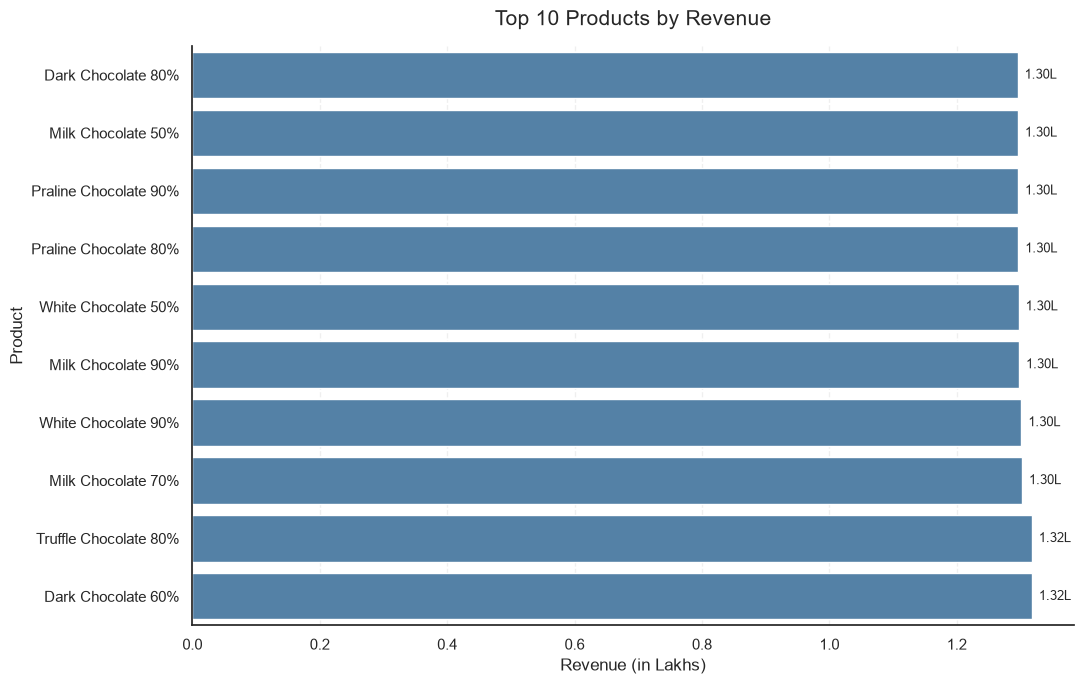

In [180]:

plt.figure(figsize=(11,7))

plot_data = (
    revenue_productwise_data
    .head(10)
    .sort_values('revenue', ascending=True)
    .copy()
)
plot_data['revenue_lakhs'] = plot_data['revenue'] / 100000

ax = sns.barplot(
    data = plot_data,
    x = 'revenue_lakhs',
    y = 'product_name',
    color = 'steelblue'
)
# add revenue labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2fL',
        padding=5,
        fontsize=9
    )
    
ax.set_title('Top 10 Products by Revenue', fontsize=15, pad=15)
ax.set_xlabel('Revenue (in Lakhs)')
ax.set_ylabel('Product')
ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()




In [181]:
display(profit_productwise_data)

,product_id,profit,product_name,brand,category,cocoa_percent,weight_g,_merge
0,P0107,52896.71,Truffle Chocolate 80%,Ferrero,Truffle,80.0,120.0,both
1,P0091,52591.75,Dark Chocolate 60%,Cadbury,Dark,60.0,200.0,both
2,P0010,52267.00,Milk Chocolate 70%,Hershey,Truffle,70.0,50.0,both
3,P0063,52177.96,Praline Chocolate 90%,Lindt,White,90.0,100.0,both
4,P0133,52155.85,Milk Chocolate 90%,Lindt,Dark,90.0,100.0,both
...,...,...,...,...,...,...,...,...
197,P0028,48652.74,Dark Chocolate 50%,Lindt,Dark,50.0,200.0,both
198,P0035,48563.30,White Chocolate 70%,Hershey,Dark,70.0,200.0,both
199,P0167,48545.77,Truffle Chocolate 80%,Godiva,White,80.0,200.0,both
200,P0178,48313.98,Praline Chocolate 80%,Hershey,Truffle,80.0,200.0,both


In [182]:
display(quantity_productwise_data[['product_id','quantity','product_name','brand','category']].head(10))

print('Top product: P0107 — Truffle Chocolate 80% by Ferrero, with 15,468 units sold.')
print('Second place: P0091 — Dark Chocolate 60% by Cadbury, with 15,457 units sold.')
print('The difference between first and second place is only 11 units.')
print('The top 10 products have quantities ranging from 15,219 to 15,468 — a relatively narrow range.')


,product_id,quantity,product_name,brand,category
0,P0107,15468,Truffle Chocolate 80%,Ferrero,Truffle
1,P0091,15457,Dark Chocolate 60%,Cadbury,Dark
2,P0021,15364,Dark Chocolate 50%,Cadbury,White
3,P0010,15333,Milk Chocolate 70%,Hershey,Truffle
4,P0008,15327,White Chocolate 90%,Godiva,Dark
5,P0104,15278,Praline Chocolate 80%,Godiva,Truffle
6,P0039,15259,Truffle Chocolate 90%,Ferrero,White
7,P0119,15241,Truffle Chocolate 50%,Ferrero,White
8,P0191,15229,Truffle Chocolate 70%,Godiva,White
9,P0116,15219,Dark Chocolate 70%,Ferrero,Dark


Top product: P0107 — Truffle Chocolate 80% by Ferrero, with 15,468 units sold.
Second place: P0091 — Dark Chocolate 60% by Cadbury, with 15,457 units sold.
The difference between first and second place is only 11 units.
The top 10 products have quantities ranging from 15,219 to 15,468 — a relatively narrow range.


In [183]:
display(revenue_productwise_data[['product_id','revenue','product_name','brand','category']].head(10))


print('''
    P0091 — Dark Chocolate 60% by Cadbury, generating 131,813.61 in revenue.
    P0107 — Truffle Chocolate 80% by Ferrero, generating 131,799.85.
    The revenue difference between the top two is just 13.76.
    P0107 ranked first in quantity but second in revenue, while P0091 ranked second in quantity but first in revenue.
''')

,product_id,revenue,product_name,brand,category
0,P0091,131813.61,Dark Chocolate 60%,Cadbury,Dark
1,P0107,131799.85,Truffle Chocolate 80%,Ferrero,Truffle
2,P0010,130258.58,Milk Chocolate 70%,Hershey,Truffle
3,P0008,130153.07,White Chocolate 90%,Godiva,Dark
4,P0133,129789.85,Milk Chocolate 90%,Lindt,Dark
5,P0017,129728.58,White Chocolate 50%,Hershey,Milk
6,P0104,129672.14,Praline Chocolate 80%,Godiva,Truffle
7,P0063,129637.50,Praline Chocolate 90%,Lindt,White
8,P0073,129625.49,Milk Chocolate 50%,Mars,Praline
9,P0140,129569.78,Dark Chocolate 80%,Lindt,Milk



    P0091 — Dark Chocolate 60% by Cadbury, generating 131,813.61 in revenue.
    P0107 — Truffle Chocolate 80% by Ferrero, generating 131,799.85.
    The revenue difference between the top two is just 13.76.
    P0107 ranked first in quantity but second in revenue, while P0091 ranked second in quantity but first in revenue.



In [184]:
display(profit_productwise_data[['product_id','profit','product_name','brand','category']].head(10))

print('''
      P0107 gives us the most profit - even tho generating the 2nd highest_Revenue and and max quantity ( BRAND- Ferrero/ category- truffle)
      P0091 2nd(profitwise) / 1st(revenuewise)/ 2nd(quantitywise)
      ''')

,product_id,profit,product_name,brand,category
0,P0107,52896.71,Truffle Chocolate 80%,Ferrero,Truffle
1,P0091,52591.75,Dark Chocolate 60%,Cadbury,Dark
2,P0010,52267.00,Milk Chocolate 70%,Hershey,Truffle
3,P0063,52177.96,Praline Chocolate 90%,Lindt,White
4,P0133,52155.85,Milk Chocolate 90%,Lindt,Dark
5,P0008,52092.31,White Chocolate 90%,Godiva,Dark
6,P0140,51987.70,Dark Chocolate 80%,Lindt,Milk
7,P0108,51863.63,Dark Chocolate 60%,Lindt,Truffle
8,P0054,51806.33,Truffle Chocolate 80%,Lindt,Praline
9,P0199,51792.44,Dark Chocolate 70%,Hershey,White



      P0107 gives us the most profit - even tho generating the 2nd highest_Revenue and and max quantity ( BRAND- Ferrero/ category- truffle)
      P0091 2nd(profitwise) / 1st(revenuewise)/ 2nd(quantitywise)
      


### Brand Level Performance

In [185]:
brand_performance = (
    quantity_productwise_data
    .groupby("brand",dropna=False)
    .agg(
        total_quantity = ('quantity',"sum")
        )
    .reset_index()
).merge(
    revenue_productwise_data
        .groupby("brand",dropna=False)
        .agg(
            total_revenue= ('revenue',"sum")
            )
        .reset_index(),
        on='brand',
        how='outer'

).merge(
    profit_productwise_data
        .groupby("brand",dropna=False)
        .agg(
            total_profit= ('profit',"sum")
            )
        .reset_index(),
        on='brand',
        how='outer'
)


display(brand_performance.sort_values('total_quantity',ascending=False))
display(brand_performance.sort_values('total_revenue',ascending=False))
display(brand_performance.sort_values('total_profit',ascending=False))

,brand,total_quantity,total_revenue,total_profit
1,Ferrero,552056,4689031.21,1876268.09
0,Cadbury,548993,4666426.41,1865555.75
4,Lindt,519702,4422825.33,1770184.54
5,Mars,489216,4151625.34,1660828.80
2,Godiva,446436,3789363.14,1514949.08
3,Hershey,414067,3519376.79,1407855.65
6,NaN,29119,247480.64,98922.72


,brand,total_quantity,total_revenue,total_profit
1,Ferrero,552056,4689031.21,1876268.09
0,Cadbury,548993,4666426.41,1865555.75
4,Lindt,519702,4422825.33,1770184.54
5,Mars,489216,4151625.34,1660828.80
2,Godiva,446436,3789363.14,1514949.08
3,Hershey,414067,3519376.79,1407855.65
6,NaN,29119,247480.64,98922.72


,brand,total_quantity,total_revenue,total_profit
1,Ferrero,552056,4689031.21,1876268.09
0,Cadbury,548993,4666426.41,1865555.75
4,Lindt,519702,4422825.33,1770184.54
5,Mars,489216,4151625.34,1660828.80
2,Godiva,446436,3789363.14,1514949.08
3,Hershey,414067,3519376.79,1407855.65
6,NaN,29119,247480.64,98922.72


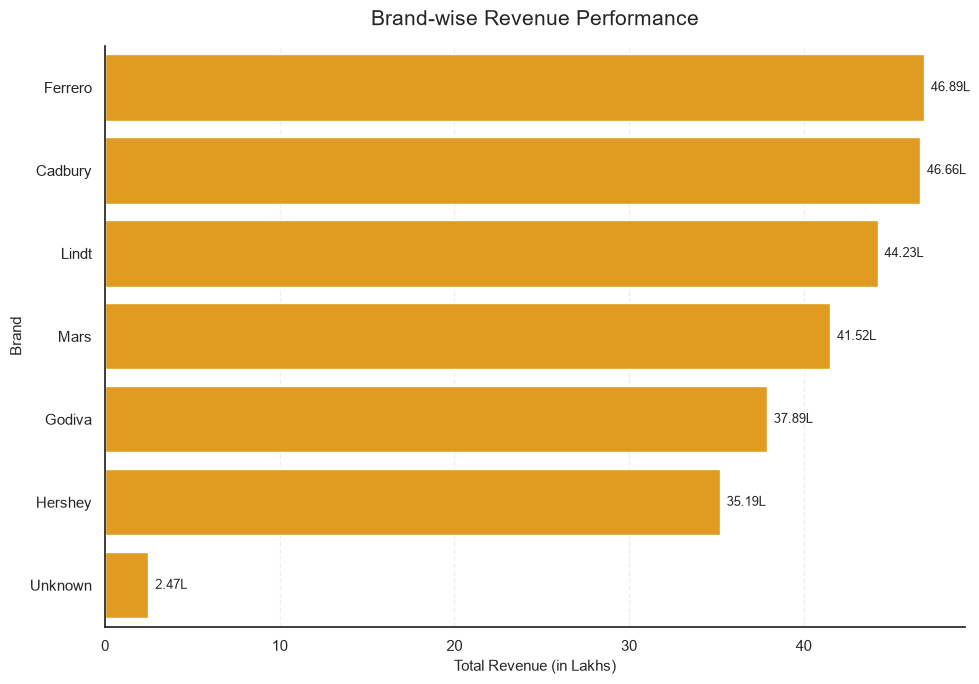

In [186]:
plot_data = (
    brand_performance[['brand', 'total_revenue']]
    .copy()
    .sort_values('total_revenue', ascending=False)
)

plot_data['brand'] = plot_data['brand'].fillna('Unknown')
plot_data['total_revenue'] = plot_data['total_revenue'] / 100000

plt.figure(figsize=(10, 7))

ax = sns.barplot(
    data=plot_data,
    x='total_revenue',
    y='brand',
    color='orange'
)

ax.set_xlabel('Total Revenue (in Lakhs)', fontsize=11)
ax.set_ylabel('Brand', fontsize=11)
ax.set_title('Brand-wise Revenue Performance', fontsize=15, pad=15)

ax.grid(axis='x', linestyle='--', alpha=0.3)
# ax.set_axisbelow(True)

for hbar in ax.containers:
    ax.bar_label(hbar, fmt='%.2fL', padding=5, fontsize=9)

sns.despine()
plt.tight_layout()
plt.show()

### Category level analysis

In [187]:
category_performance = (
    quantity_productwise_data
    .groupby("category", dropna=False)
    .agg(total_quantity=("quantity", "sum"))
    .reset_index()
    .merge(
        revenue_productwise_data
        .groupby("category", dropna=False)
        .agg(total_revenue=("revenue", "sum"))
        .reset_index(),
        on="category",
        how="outer"
    )
    .merge(
        profit_productwise_data
        .groupby("category", dropna=False)
        .agg(total_profit=("profit", "sum"))
        .reset_index(),
        on="category",
        how="outer"
    )
)

display(
    category_performance.sort_values(
        "total_revenue",
        ascending=False
    )
)

,category,total_quantity,total_revenue,total_profit
2,Praline,784435,6665641.32,2665242.79
4,White,714967,6070172.20,2428117.37
0,Dark,623247,5298123.27,2120672.08
3,Truffle,462202,3924343.24,1569202.54
1,Milk,385619,3280368.19,1312407.13
5,NaN,29119,247480.64,98922.72


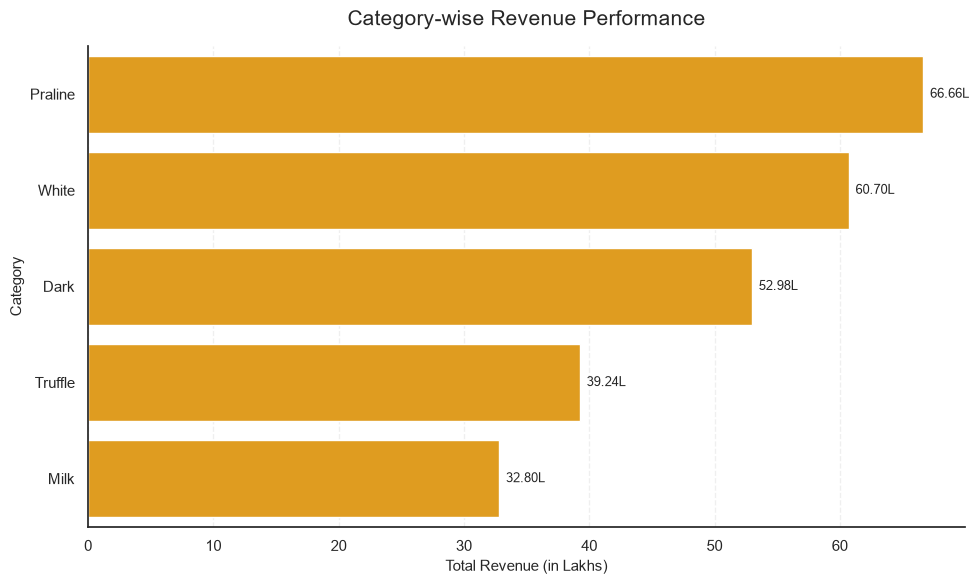

In [188]:
plot_data = (
    category_performance[['category', 'total_revenue']]
    .copy()
    .sort_values('total_revenue', ascending=False)
)

plot_data['total_revenue'] = plot_data['total_revenue'] / 100000

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=plot_data,
    x='total_revenue',
    y='category',
    color='orange'
)

ax.set_title('Category-wise Revenue Performance', fontsize=15, pad=15)
ax.set_xlabel('Total Revenue (in Lakhs)', fontsize=11)
ax.set_ylabel('Category', fontsize=11)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2fL',
        padding=5,
        fontsize=9
    )

ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()

In [189]:
cocoa_analysis = (
    quantity_productwise_data[['product_id', 'quantity']]
).merge(
    revenue_productwise_data[['product_id','revenue']],
    on = 'product_id',
    how = 'left'
).merge(
    profit_productwise_data[['product_id','profit']],
        on = 'product_id',
        how = 'left'
).merge(
    df_products[['product_id','cocoa_percent','category','brand','weight_g']],
    on='product_id',
    how='left',    
)

display(cocoa_analysis.head())
display(cocoa_analysis.info())

,product_id,quantity,revenue,profit,cocoa_percent,category,brand,weight_g
0,P0107,15468,131799.85,52896.71,80.0,Truffle,Ferrero,120.0
1,P0091,15457,131813.61,52591.75,60.0,Dark,Cadbury,200.0
2,P0021,15364,128555.15,51298.91,50.0,White,Cadbury,50.0
3,P0010,15333,130258.58,52267.00,70.0,Truffle,Hershey,50.0
4,P0008,15327,130153.07,52092.31,90.0,Dark,Godiva,100.0


<class 'pandas.DataFrame'>
RangeIndex: 202 entries, 0 to 201
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   product_id     202 non-null    str    
 1   quantity       202 non-null    int64  
 2   revenue        202 non-null    float64
 3   profit         202 non-null    float64
 4   cocoa_percent  200 non-null    float64
 5   category       200 non-null    str    
 6   brand          200 non-null    str    
 7   weight_g       200 non-null    float64
dtypes: float64(4), int64(1), str(3)
memory usage: 12.8 KB


None

In [190]:
weight_performance = (
    cocoa_analysis
    .groupby('weight_g')
    .agg(
        total_products=('product_id', 'nunique'),
        total_quantity=('quantity', 'sum'),
        total_revenue=('revenue', 'sum'),
        total_profit=('profit', 'sum')
    )
    .reset_index()
    .sort_values('weight_g')
)

display(weight_performance)

,weight_g,total_products,total_quantity,total_revenue,total_profit
0,50.0,48,713691,6061505.42,2424995.78
1,80.0,31,460309,3907572.98,1561878.52
2,100.0,47,699937,5948333.40,2380097.57
3,120.0,36,535330,4551126.59,1821367.96
4,200.0,38,561203,4770109.83,1907302.08


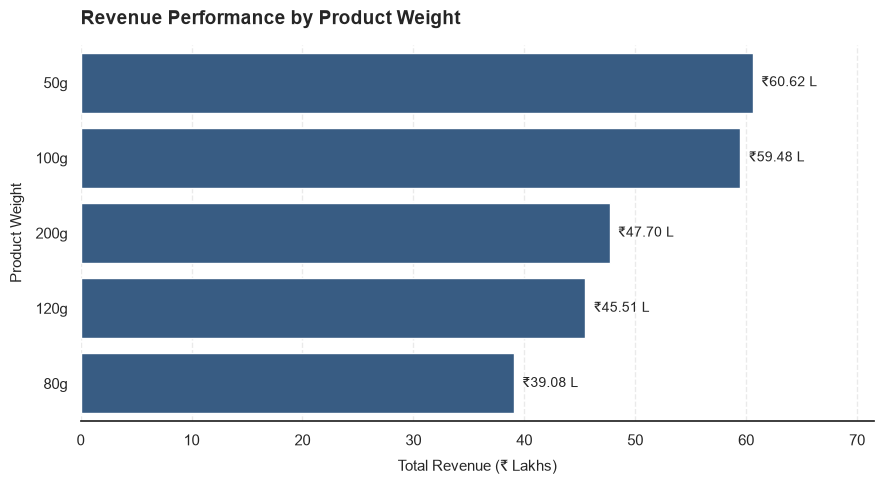

In [191]:
# 1. Prepare data
plot_data = weight_performance.copy()
plot_data['revenue_lakhs'] = plot_data['total_revenue'] / 100000

# Format weight as clean category labels and sort by revenue descending
plot_data['weight_label'] = plot_data['weight_g'].astype(int).astype(str) + 'g'
plot_data = plot_data.sort_values('revenue_lakhs', ascending=False)

# 2. Plot setup
plt.figure(figsize=(9, 5))
sns.set_theme(style='white', font_scale=1.0)

ax = sns.barplot(
    data=plot_data,
    x='revenue_lakhs',
    y='weight_label',
    color='#2b5c8f'
)

# 3. Titles and Labels
ax.set_title('Revenue Performance by Product Weight', fontsize=14, weight='bold', pad=15, loc='left')
ax.set_xlabel('Total Revenue (₹ Lakhs)', fontsize=11, labelpad=8)
ax.set_ylabel('Product Weight', fontsize=11, labelpad=8)

# 4. Direct bar labels (formatted cleanly)
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='₹%.2f L',
        padding=6,
        fontsize=10,
        weight='medium'
    )

# 5. Styling & Clean-up
ax.set_xlim(0, plot_data['revenue_lakhs'].max() * 1.18)  # Leave room for labels
ax.grid(axis='x', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)
sns.despine(left=True, bottom=False)
ax.tick_params(left=False)  # Remove y-axis tick marks for a cleaner look

plt.tight_layout()
plt.show()

### comparing performance based on cocoa_percentage

In [192]:
cocoa_performance = (
    cocoa_analysis
    .groupby('cocoa_percent')
    .agg(
        total_quantity=('quantity', 'sum'),
        total_revenue=('revenue', 'sum'),
        total_profit=('profit', 'sum'),
        product_count=('product_id', 'nunique')
    )
    .reset_index()
    .sort_values('cocoa_percent')
)

display(cocoa_performance)

,cocoa_percent,total_quantity,total_revenue,total_profit,product_count
0,50.0,760010,6455441.68,2582014.34,51
1,60.0,444629,3781587.20,1513050.54,30
2,70.0,636940,5417442.63,2166117.46,43
3,80.0,549542,4669477.10,1867688.75,37
4,90.0,579349,4914699.61,1966770.82,39


In [193]:
cocoa_performance['avg_quantity_per_product'] = (
    cocoa_performance['total_quantity']
    / cocoa_performance['product_count']
)

cocoa_performance['avg_revenue_per_product'] = (
    cocoa_performance['total_revenue']
    / cocoa_performance['product_count']
)

cocoa_performance['avg_profit_per_product'] = (
    cocoa_performance['total_profit']
    / cocoa_performance['product_count']
)

display(
    cocoa_performance.round(2)
    .sort_values('avg_revenue_per_product', ascending=False)
)

,cocoa_percent,total_quantity,total_revenue,total_profit,product_count,avg_quantity_per_product,avg_revenue_per_product,avg_profit_per_product
0,50.0,760010,6455441.68,2582014.34,51,14902.16,126577.29,50627.73
3,80.0,549542,4669477.10,1867688.75,37,14852.49,126202.08,50478.07
1,60.0,444629,3781587.20,1513050.54,30,14820.97,126052.91,50435.02
4,90.0,579349,4914699.61,1966770.82,39,14855.10,126017.94,50430.02
2,70.0,636940,5417442.63,2166117.46,43,14812.56,125987.04,50374.82


## Customers Datset audit

In [194]:
display(df_customers)
df_customers.info()
display(df_customers.describe(include='all').T)

# join date is stored as string and loyalty member as binary value

,customer_id,age,gender,loyalty_member,join_date
0,C000001,40,Male,1,2025-05-21
1,C000002,47,Male,0,2021-12-26
2,C000003,58,Female,1,2022-09-13
3,C000004,25,Female,0,2025-02-27
4,C000005,43,Male,0,2023-08-31
...,...,...,...,...,...
49995,C049996,30,Female,1,2022-11-21
49996,C049997,24,Female,0,2022-08-30
49997,C049998,53,Male,0,2024-09-22
49998,C049999,31,Female,1,2025-08-23


<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   customer_id     50000 non-null  str  
 1   age             50000 non-null  int64
 2   gender          50000 non-null  str  
 3   loyalty_member  50000 non-null  int64
 4   join_date       50000 non-null  str  
dtypes: int64(2), str(3)
memory usage: 1.9 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,50000,50000,C000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,50000.0,NaN,NaN,NaN,44.0261,15.328333,18.0,31.0,44.0,57.0,70.0
gender,50000,2,Male,25242,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loyalty_member,50000.0,NaN,NaN,NaN,0.50208,0.500001,0.0,0.0,1.0,1.0,1.0
join_date,50000,1827,2023-09-06,46,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Age group classification

In [195]:
# since max age is 70 n min is 18
df_customers['age_group'] = pd.cut(
    df_customers['age'],
    bins = [17,25,35,45,55,70],
    labels= ['18-25','26-35','36-45','46-55','56-70']
)


In [196]:
age_information = df_customers['age_group'].value_counts().reset_index()

age_information['percentage_of_total'] = (( age_information['count'] /age_information['count'].sum() )*100).round(2)

display(age_information)


,age_group,count,percentage_of_total
0,56-70,14260,28.52
1,36-45,9452,18.90
2,46-55,9378,18.76
3,26-35,9275,18.55
4,18-25,7635,15.27


maximum age-group is from 56-70 with 28.52% n smallest segment is 18-25 which should be eating the chocolates most

In [197]:
sales_with_age = df_sales[['order_id','order_date','product_id','store_id','customer_id','quantity','unit_price','discount','revenue','cost','profit']].merge(
    df_customers[['customer_id','age_group']],
    on = 'customer_id',
    how = 'left'
)


age_spending_analysis = (
    sales_with_age
    .groupby('age_group')
    .agg(
        unique_customers=('customer_id', 'nunique'),
        total_orders=('order_id', 'nunique'),
        total_revenue=('revenue', 'sum'),
        total_profit=('profit', 'sum')
    )
    .reset_index()
)

age_spending_analysis['revenue_per_customer'] = (
    age_spending_analysis['total_revenue']
    / age_spending_analysis['unique_customers']
)

age_spending_analysis['revenue_per_order'] = (
    age_spending_analysis['total_revenue']
    / age_spending_analysis['total_orders']
)




gender_information = (
    df_customers['gender']
    .value_counts()
    .rename_axis('gender')
    .reset_index(name='customer_count')
)

gender_information['percentage_of_total'] = (
    gender_information['customer_count']
    / gender_information['customer_count'].sum() * 100
).round(2)




loyalty_information = (
    df_customers['loyalty_member']
    .value_counts()
    .rename_axis('loyalty_member')
    .reset_index(name='customer_count')
)

loyalty_information['percentage_of_total'] = (
    loyalty_information['customer_count']
    / loyalty_information['customer_count'].sum() * 100
).round(2)

display(age_spending_analysis.round(2).sort_values('revenue_per_customer',ascending=False))
display(gender_information)
display(loyalty_information)

,age_group,unique_customers,total_orders,total_revenue,total_profit,revenue_per_customer,revenue_per_order
4,56-70,14260,285942,7286028.22,2914248.49,510.94,25.48
1,26-35,9275,185700,4733427.26,1894800.96,510.34,25.49
3,46-55,9378,187550,4776723.79,1910728.04,509.35,25.47
0,18-25,7635,152419,3884290.46,1552629.42,508.75,25.48
2,36-45,9452,188389,4805659.13,1922157.72,508.43,25.51


,gender,customer_count,percentage_of_total
0,Male,25242,50.48
1,Female,24758,49.52


,loyalty_member,customer_count,percentage_of_total
0,1,25104,50.21
1,0,24896,49.79


### gender information

In [198]:
sales_with_customer = df_sales[
    ['order_id', 'customer_id', 'quantity', 'revenue', 'profit']
].merge(
    df_customers[['customer_id', 'gender', 'loyalty_member']],
    on='customer_id',
    how='left'
)

sales_by_gender = (
    sales_with_customer
    .groupby('gender')
    .agg(
        unique_customers=('customer_id', 'nunique'),
        total_orders=('order_id', 'nunique'),
        total_quantity=('quantity', 'sum'),
        total_revenue=('revenue', 'sum'),
        total_profit=('profit', 'sum')
    )
    .reset_index()
)

sales_by_gender['revenue_per_customer'] = (
    sales_by_gender['total_revenue']
    / sales_by_gender['unique_customers']
)

display(sales_by_gender.round(2))

,gender,unique_customers,total_orders,total_quantity,total_revenue,total_profit,revenue_per_customer
0,Female,24758,495689,1486276,12630103.60,5053023.43,510.14
1,Male,25242,504311,1513313,12856025.26,5141541.20,509.31


In [199]:
sales_by_loyalty = (
    sales_with_customer
    .groupby('loyalty_member')
    .agg(
        unique_customers=('customer_id', 'nunique'),
        total_orders=('order_id', 'nunique'),
        total_quantity=('quantity', 'sum'),
        total_revenue=('revenue', 'sum'),
        total_profit=('profit', 'sum')
    )
    .reset_index()
)

sales_by_loyalty['revenue_per_customer'] = (
    sales_by_loyalty['total_revenue']
    / sales_by_loyalty['unique_customers']
)

sales_by_loyalty['revenue_per_order'] = (
    sales_by_loyalty['total_revenue']
    / sales_by_loyalty['total_orders']
)

display(sales_by_loyalty.round(2))

,loyalty_member,unique_customers,total_orders,total_quantity,total_revenue,total_profit,revenue_per_customer,revenue_per_order
0,0,24896,498102,1494525,12713088.39,5085560.24,510.65,25.52
1,1,25104,501898,1505064,12773040.47,5109004.39,508.80,25.45


## Store-City Analysis

In [200]:
display(df_stores.head(5))
display(df_stores.info())

display(df_stores.describe(include='all').T)
# describes tell us count, unique, top and freq

,store_id,store_name,city,country,store_type
0,S001,Chocolate Store 1,New York,Canada,Retail
1,S002,Chocolate Store 2,Melbourne,Canada,Mall
2,S003,Chocolate Store 3,Berlin,France,Mall
3,S004,Chocolate Store 4,Paris,UK,Airport
4,S005,Chocolate Store 5,Sydney,USA,Online


<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   store_id    100 non-null    str  
 1   store_name  100 non-null    str  
 2   city        100 non-null    str  
 3   country     100 non-null    str  
 4   store_type  100 non-null    str  
dtypes: str(5)
memory usage: 4.0 KB


None

,count,unique,top,freq
store_id,100,100,S001,1
store_name,100,100,Chocolate Store 1,1
city,100,7,Toronto,18
country,100,6,Canada,20
store_type,100,4,Airport,30


sales data with store

In [201]:
sales_with_store = (
    df_sales[['order_id','store_id','quantity','revenue','profit']]
    .merge(
        df_stores,
        on = 'store_id',
        how = 'left',
        indicator=True
    )
)

display(sales_with_store.head(2))
display(sales_with_store['_merge'].value_counts())



,order_id,store_id,quantity,revenue,profit,store_name,city,country,store_type,_merge
0,0RD00000001,S093,5,61.33,18.56,Chocolate Store 93,Sydney,UK,Airport,both
1,0RD00000002,S065,3,36.03,16.97,Chocolate Store 65,New York,Australia,Retail,both


_merge
both          1000000
left_only           0
right_only          0
Name: count, dtype: int64

this tell us store id are proper and every store_id has its associated details in the store_table

citywise_performance

In [202]:
# checking data inconsistency
df_stores.groupby(['country', 'city']).size().reset_index(name='count')

,country,city,count
0,Australia,Berlin,2
1,Australia,London,2
2,Australia,Melbourne,1
3,Australia,New York,2
4,Australia,Paris,2
5,Australia,Sydney,2
6,Australia,Toronto,4
7,Canada,London,4
8,Canada,Melbourne,3
9,Canada,New York,2


In [203]:
print("Countries: ",sorted(df_stores['country'].unique().tolist()))
print("Cities: ",sorted(df_stores['city'].unique().tolist()))

Countries:  ['Australia', 'Canada', 'France', 'Germany', 'UK', 'USA']
Cities:  ['Berlin', 'London', 'Melbourne', 'New York', 'Paris', 'Sydney', 'Toronto']


In [204]:
display(
    df_stores[['store_id', 'country', 'city']]
    .sort_values(['country', 'city'])
    .head(10)
)

print(df_stores.columns.tolist())
display(df_stores.head())

,store_id,country,city
35,S036,Australia,Berlin
85,S086,Australia,Berlin
13,S014,Australia,London
27,S028,Australia,London
28,S029,Australia,Melbourne
64,S065,Australia,New York
97,S098,Australia,New York
30,S031,Australia,Paris
59,S060,Australia,Paris
62,S063,Australia,Sydney


['store_id', 'store_name', 'city', 'country', 'store_type']


,store_id,store_name,city,country,store_type
0,S001,Chocolate Store 1,New York,Canada,Retail
1,S002,Chocolate Store 2,Melbourne,Canada,Mall
2,S003,Chocolate Store 3,Berlin,France,Mall
3,S004,Chocolate Store 4,Paris,UK,Airport
4,S005,Chocolate Store 5,Sydney,USA,Online


In [205]:
valid_city_country = {
    'New York' : 'USA',
    'Toronto' : 'Canada',
    'Berlin' : 'Germany',
    'London' : 'UK',
    'Melbourne' : 'Australia',
    'Paris' : 'France',
    'Sydney' : 'Australia'
}

df_stores['expected_country'] = df_stores['city'].map(valid_city_country)
df_stores['location_mismatch'] = (
    df_stores['country'] != df_stores['expected_country']
)

display(df_stores.head(2))
display(df_stores['location_mismatch'].value_counts())

,store_id,store_name,city,country,store_type,expected_country,location_mismatch
0,S001,Chocolate Store 1,New York,Canada,Retail,USA,True
1,S002,Chocolate Store 2,Melbourne,Canada,Mall,Australia,True


location_mismatch
True     80
False    20
Name: count, dtype: int64

In [206]:
city_performance = (
    sales_with_store
    .groupby(['country', 'city'])
    .agg(
        total_stores=('store_id', 'nunique'),
        total_orders=('order_id', 'nunique'),
        total_quantity=('quantity', 'sum'),
        total_revenue=('revenue', 'sum'),
        total_profit=('profit', 'sum')
    )
    .reset_index()
    .sort_values('total_revenue', ascending=False)
)

display(city_performance.round(2).head(10))

,country,city,total_stores,total_orders,total_quantity,total_revenue,total_profit
12,Canada,Toronto,6,59880,179613,1524861.29,609059.19
31,UK,Paris,5,49307,147929,1255058.46,502407.01
6,Australia,Toronto,4,40286,121055,1027853.23,411606.12
36,USA,Melbourne,4,40056,120223,1026666.26,410475.97
39,USA,Sydney,4,40094,120545,1025942.94,410546.79
19,France,Toronto,4,40165,120378,1025140.12,409804.39
7,Canada,London,4,39997,119890,1015609.90,405840.96
37,USA,New York,4,39810,119574,1014689.45,405769.56
30,UK,New York,3,30183,90759,773096.50,309026.43
14,France,London,3,29931,89872,768404.50,307582.96


### Performance of store (Store Typewise)

In [207]:
storeType_performance = (
    sales_with_store
    .groupby('store_type')
    .agg(
        total_stores = ('store_id','nunique'),
        total_orders = ('order_id','nunique'),
        total_quantity = ('quantity','sum'),
        total_revenue = ('revenue','sum'),
        total_profit = ('profit','sum')
    )
    .reset_index()
    
)

storeType_performance['revenue_per_store'] = (
    storeType_performance['total_revenue']
    / storeType_performance['total_stores']
)
storeType_performance['profit_per_store'] = (
    storeType_performance['total_profit']
    / storeType_performance['total_stores']
)


display(storeType_performance.round(2).sort_values('total_revenue',ascending=False))

,store_type,total_stores,total_orders,total_quantity,total_revenue,total_profit,revenue_per_store,profit_per_store
0,Airport,30,299119,896417,7613875.92,3046173.74,253795.86,101539.12
1,Mall,26,260061,780511,6628228.67,2650844.14,254931.87,101955.54
2,Online,25,250332,751100,6386035.76,2554237.38,255441.43,102169.50
3,Retail,19,190488,571561,4857988.51,1943309.37,255683.61,102279.44


# Calendar & Seasonality

In [208]:
df_seasonality = df_sales.copy()
df_seasonality['day_of_week'] = df_seasonality['order_date'].dt.day_name()
df_seasonality['month_num'] = df_seasonality['order_date'].dt.month
df_seasonality['month'] = df_seasonality['order_date'].dt.month_name()
df_seasonality['year'] = df_seasonality['order_date'].dt.year
display(df_seasonality.head(5))


,order_id,order_date,product_id,store_id,customer_id,quantity,unit_price,discount,revenue,cost,profit,calculated_revenue,calculated_profit,day_of_week,month_num,month,year
0,0RD00000001,2023-01-07,P0080,S093,C040749,5,14.43,0.15,61.33,42.77,18.56,61.33,18.56,Saturday,1,January,2023
1,0RD00000002,2023-10-22,P0173,S065,C020161,3,12.01,0.00,36.03,19.06,16.97,36.03,16.97,Sunday,10,October,2023
2,0RD00000003,2023-05-07,P0115,S078,C048069,2,10.02,0.00,20.04,10.29,9.75,20.04,9.75,Sunday,5,May,2023
3,0RD00000004,2024-06-23,P0186,S088,C047901,2,14.66,0.10,26.39,16.35,10.04,26.39,10.04,Sunday,6,June,2024
4,0RD00000005,2024-09-24,P0197,S054,C033950,1,12.34,0.00,12.34,7.94,4.40,12.34,4.40,Tuesday,9,September,2024


In [209]:

sales_by_weekday = (
    df_seasonality
    .groupby('day_of_week')
    .agg(
        total_days = ('order_date','nunique'),
        total_orders = ('order_id','nunique'),
        total_revenue = ('revenue','sum'),
        total_profit = ('profit','sum'),
        total_quantity = ('quantity','sum'),
    )
    .reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
    .reset_index()
)
sales_by_weekday['avg_day_revenue'] = (sales_by_weekday['total_revenue'] / sales_by_weekday['total_days'])
sales_by_weekday['avg_day_profit'] = (sales_by_weekday['total_profit'] / sales_by_weekday['total_days'])
sales_by_weekday['avg_day_quantity'] = (sales_by_weekday['total_quantity'] / sales_by_weekday['total_days'])
sales_by_weekday['avg_day_orders'] = (sales_by_weekday['total_orders'] / sales_by_weekday['total_days'])

display(sales_by_weekday[['day_of_week','avg_day_revenue','avg_day_profit','avg_day_quantity','avg_day_orders']].round(2).sort_values('avg_day_revenue',ascending=False))


,day_of_week,avg_day_revenue,avg_day_profit,avg_day_quantity,avg_day_orders
1,Tuesday,34982.97,13995.37,4112.07,1371.10
5,Saturday,34944.97,13978.17,4114.27,1372.51
4,Friday,34901.55,13959.66,4102.22,1368.11
6,Sunday,34817.76,13933.19,4100.26,1368.56
2,Wednesday,34810.76,13919.42,4098.54,1364.42
0,Monday,34806.14,13913.68,4096.96,1365.02
3,Thursday,34788.94,13922.84,4099.53,1366.19


Weekday analysis — findings
- Tuesday has the highest average daily revenue: $34,982.97.
- Thursday has the lowest: $34,788.94.
- The difference is only $194.03 per day, approximately 0.56% of Tuesday's revenue.
- Saturday has the highest average daily order volume (1,372.51), despite ranking second in revenue.
- Tuesday leads in average daily profit as well ($13,995.37).
- Average daily quantity is also very similar across all seven days.

In [210]:
#by month
sales_by_month = (
    df_seasonality
    .groupby('month')
    .agg(
        total_days = ('order_date','nunique'),
        total_orders=('order_id', 'nunique'),
        total_revenue=('revenue', 'sum'),
        total_profit=('profit', 'sum'),
        total_quantity=('quantity', 'sum')
    )
    .reset_index()
    .sort_values('total_revenue', ascending=False)
)

sales_by_month['avg_day_revenue'] = (sales_by_month['total_revenue'] / sales_by_month['total_days'])
sales_by_month['avg_day_profit'] = (sales_by_month['total_profit'] / sales_by_month['total_days'])
sales_by_month['avg_day_quantity'] = (sales_by_month['total_quantity'] / sales_by_month['total_days'])
sales_by_month['avg_day_orders'] = (sales_by_month['total_orders'] / sales_by_month['total_days'])

display(sales_by_month[['month','avg_day_revenue','avg_day_profit','avg_day_quantity','avg_day_orders']].round(2).sort_values('avg_day_revenue',ascending=False))

,month,avg_day_revenue,avg_day_profit,avg_day_quantity,avg_day_orders
4,January,35157.58,14060.26,4131.65,1377.02
11,September,35139.16,14047.43,4127.05,1374.42
7,March,34987.37,13997.31,4111.03,1370.45
5,July,34986.23,13987.52,4113.90,1370.00
1,August,34984.57,14004.38,4117.42,1369.89
8,May,34871.97,13950.78,4109.16,1371.35
2,December,34801.55,13909.91,4096.27,1365.56
6,June,34737.65,13902.55,4090.98,1363.22
3,February,34719.14,13878.81,4091.72,1364.61
0,April,34697.97,13889.48,4084.65,1360.20


A few observations:
- January leads in average daily revenue and profit.
- September has the highest daily order volume, but doesn't lead in revenue.
- August has the highest average daily quantity.
- February is no longer the weakest month once we normalize for the number of days.
- The difference between January and October is approximately 1.53%, so monthly performance is also fairly consistent.

In [211]:
monthly_year_comparison = (
    df_seasonality
    .groupby(['year', 'month_num', 'month'])
    .agg(
        total_days = ('order_date','nunique'),
        total_orders=('order_id', 'nunique'),
        total_revenue=('revenue', 'sum'),
        total_profit=('profit', 'sum'),
        total_quantity=('quantity', 'sum')
    )
    .reset_index()
    .sort_values(['year','month_num'])
) 

display(monthly_year_comparison.round(2))
# checking growth pct revenue wise

pivoted_myc = monthly_year_comparison.pivot(
    index='month_num',
    columns='year',
    values= 'total_revenue'
)
pivoted_myc['growth_pct'] = (pivoted_myc[2024] - pivoted_myc[2023]) / pivoted_myc[2023] * 100
display(pivoted_myc.round(2))

,year,month_num,month,total_days,total_orders,total_revenue,total_profit,total_quantity
0,2023,1,January,31,42907,1095019.20,438230.77,128486
1,2023,2,February,28,38112,968948.95,387259.34,114154
2,2023,3,March,31,42446,1084656.09,433765.09,127279
3,2023,4,April,30,40831,1038425.32,415827.16,122274
4,2023,5,May,31,42566,1083418.79,433491.77,127781
5,2023,6,June,30,41082,1046045.02,418154.90,123276
6,2023,7,July,31,42393,1083223.13,432958.32,127294
7,2023,8,August,31,42477,1086689.94,434989.24,127634
8,2023,9,September,30,41240,1056935.75,422089.21,123993
9,2023,10,October,31,42387,1071879.65,428744.79,126607


year,2023,2024,growth_pct
month_num,,,
1,1095019.20,1084751.00,-0.94
2,968948.95,1010042.22,4.24
3,1084656.09,1084560.82,-0.01
4,1038425.32,1043453.14,0.48
5,1083418.79,1078643.18,-0.44
6,1046045.02,1038214.24,-0.75
7,1083223.13,1085923.34,0.25
8,1086689.94,1082353.60,-0.40
9,1056935.75,1051414.03,-0.52


In [212]:
display(monthly_year_comparison.sort_values('total_revenue',ascending=False))
# display(monthly_year_comparison['year'])
# display(monthly_year_comparison[['year']])

,year,month_num,month,total_days,total_orders,total_revenue,total_profit,total_quantity
0,2023,1,January,31,42907,1095019.20,438230.77,128486
7,2023,8,August,31,42477,1086689.94,434989.24,127634
18,2024,7,July,31,42547,1085923.34,434268.21,127768
12,2024,1,January,31,42468,1084751.00,433505.26,127676
2,2023,3,March,31,42446,1084656.09,433765.09,127279
14,2024,3,March,31,42522,1084560.82,434068.29,127605
4,2023,5,May,31,42566,1083418.79,433491.77,127781
6,2023,7,July,31,42393,1083223.13,432958.32,127294
19,2024,8,August,31,42456,1082353.60,433282.13,127646
11,2023,12,December,31,42259,1080446.31,432020.66,126886


January revenue decreased from 1,095,019.20 in 2023 to 1,084,751.00 in 2024.



February improved substantially, from 968,948.95 to 1,010,042.22.



March was almost unchanged between the two years.



July increased slightly, while August and September declined.



December revenue decreased from 1,080,446.31 to 1,077,249.72, despite having slightly more orders in 2024.

## Visualization

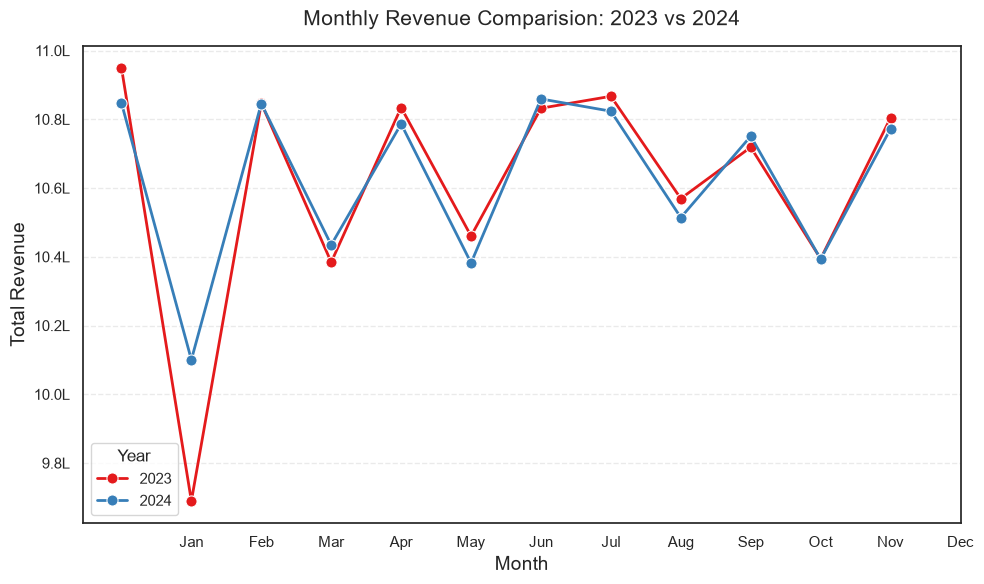

In [213]:
plt.figure(figsize=(10,6))

sns.lineplot(
    data = monthly_year_comparison,
    x = 'month',
    y = 'total_revenue',
    hue = 'year',
    linewidth = 2,
    marker = 'o',
    markersize = 8,
    palette = 'Set1'
    
)
# from matplotlib.ticker import FuncFormatter

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'{x/100000:.1f}L')
)

plt.title('Monthly Revenue Comparision: 2023 vs 2024',fontsize = 15, pad=15)

plt.ylabel('Total Revenue',fontsize = 14)
plt.xlabel('Month',fontsize = 14)
plt.xticks(
    ticks= range(1,13),
    labels = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
)
plt.legend(title = 'Year')
plt.grid(axis='y',linestyle = '--',alpha = 0.4)
plt.tight_layout()
plt.show()

## Investigating Holidays (Christmas / Thanksgiving)

In [214]:
df_sales['order_date'].duplicated().sum()
# thereby we have multiple records for one date

np.int64(999269)

In [215]:
daily_sales = (
    df_sales
    .groupby('order_date')
    .agg(
        total_revenue=('revenue', 'sum'),
        total_profit=('profit', 'sum'),
        total_orders=('order_id', 'nunique')
    )
    .reset_index()
) # grouped by dates and we get total (revenue/profit/quantity) for that date

daily_sales['year'] = daily_sales['order_date'].dt.year
daily_sales['month'] = daily_sales['order_date'].dt.month

daily_sales['period'] = 'Regular days'
display(daily_sales.head(10))



# Christmas: December 20–26
for year in [2023,2024]:
    christmas_mask = daily_sales['order_date'].between(
        pd.Timestamp(f'{year}-12-20'),pd.Timestamp(f'{year}-12-26')
    )
    daily_sales.loc[christmas_mask,'period'] = 'Christmas window'
    
daily_sales.loc[daily_sales['period'] == 'Christmas window',:]

# Thanksgiving window  3days before n after thanksgiving

thanksgiving_dates = {  # dict to stores dates for each year
    2023 : pd.Timestamp('2023-11-23'),
    2024 : pd.Timestamp('2024-11-28')
}


for year,thanksgiving_date in thanksgiving_dates.items(): # acessing the key n value pair from the dict 
    thanksgiving_mask = daily_sales['order_date'].between(
        thanksgiving_date - pd.Timedelta(days=3), # 3 days prior
        thanksgiving_date + pd.Timedelta(days=3) # 3 days later
    )
    daily_sales.loc[thanksgiving_mask,'period'] = 'Thanksgiving window'

display(daily_sales.loc[daily_sales['period'] == 'Thanksgiving window'])

# practicing dictionary functions
for key,value in thanksgiving_dates.items():
    print(f'{key}: {value}')

,order_date,total_revenue,total_profit,total_orders,year,month,period
0,2023-01-01,35166.07,14064.89,1372,2023,1,Regular days
1,2023-01-02,36118.51,14403.11,1387,2023,1,Regular days
2,2023-01-03,34354.56,13742.00,1356,2023,1,Regular days
3,2023-01-04,35372.93,14196.01,1363,2023,1,Regular days
4,2023-01-05,35024.87,14011.88,1367,2023,1,Regular days
5,2023-01-06,36439.96,14605.98,1429,2023,1,Regular days
6,2023-01-07,34436.39,13743.87,1371,2023,1,Regular days
7,2023-01-08,36920.19,14770.96,1438,2023,1,Regular days
8,2023-01-09,34256.18,13670.87,1338,2023,1,Regular days
9,2023-01-10,34478.13,13772.36,1361,2023,1,Regular days


,order_date,total_revenue,total_profit,total_orders,year,month,period
323,2023-11-20,33845.38,13529.43,1331,2023,11,Thanksgiving window
324,2023-11-21,34901.35,13985.93,1394,2023,11,Thanksgiving window
325,2023-11-22,34508.20,13774.24,1353,2023,11,Thanksgiving window
326,2023-11-23,35355.77,14277.38,1368,2023,11,Thanksgiving window
327,2023-11-24,33242.43,13283.03,1298,2023,11,Thanksgiving window
328,2023-11-25,32684.58,13167.54,1338,2023,11,Thanksgiving window
329,2023-11-26,33739.56,13531.14,1346,2023,11,Thanksgiving window
694,2024-11-25,34743.47,13859.77,1365,2024,11,Thanksgiving window
695,2024-11-26,35726.26,14337.76,1388,2024,11,Thanksgiving window
696,2024-11-27,35103.22,13953.26,1368,2024,11,Thanksgiving window


2023: 2023-11-23 00:00:00
2024: 2024-11-28 00:00:00


In [216]:
holiday_comparison = (
    daily_sales
    .groupby(['year', 'month', 'period'])
    .agg(
        days=('order_date', 'nunique'),
        avg_daily_revenue=('total_revenue', 'mean'),
        avg_daily_profit=('total_profit', 'mean'),
        avg_daily_orders=('total_orders', 'mean')
    )
    .reset_index()
    .sort_values('avg_daily_revenue',ascending=False)
    
)

display(holiday_comparison.round(2))

,year,month,period,days,avg_daily_revenue,avg_daily_profit,avg_daily_orders
0,2023,1,Regular days,31,35323.20,14136.48,1384.10
8,2023,9,Regular days,30,35231.19,14069.64,1374.67
7,2023,8,Regular days,31,35054.51,14031.91,1370.23
22,2024,9,Regular days,30,35047.13,14025.23,1374.17
20,2024,7,Regular days,31,35029.79,14008.65,1372.48
14,2024,1,Regular days,31,34991.97,13984.04,1369.94
2,2023,3,Regular days,31,34988.91,13992.42,1369.23
16,2024,3,Regular days,31,34985.83,14002.20,1371.68
13,2023,12,Regular days,24,34955.77,13971.86,1367.17
4,2023,5,Regular days,31,34948.99,13983.61,1373.10


In [217]:
period_comparison = (
    daily_sales.groupby('period')
    .agg(
        avg_daily_revenue=('total_revenue', 'mean'),
        avg_daily_profit=('total_profit', 'mean'),
        avg_daily_orders=('total_orders', 'mean')
    )
    .reset_index()
)

display(round(period_comparison,2).sort_values('avg_daily_revenue',ascending=False))

,period,avg_daily_revenue,avg_daily_profit,avg_daily_orders
1,Regular days,34879.50,13951.44,1368.55
0,Christmas window,34643.59,13883.60,1353.79
2,Thanksgiving window,34345.21,13737.90,1354.00


This suggests that the selected holiday windows do not show a noticeable sales uplift compared with regular days.

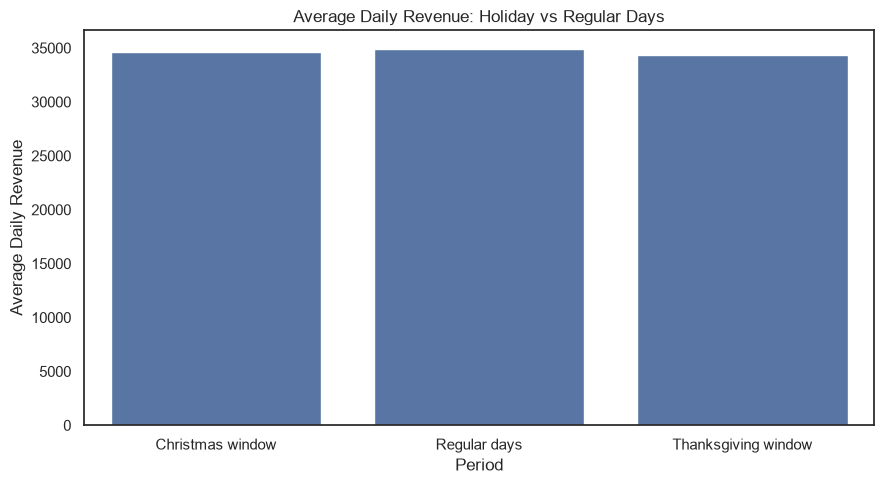

In [218]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=period_comparison,
    x='period',
    y='avg_daily_revenue'
)

plt.title('Average Daily Revenue: Holiday vs Regular Days')
plt.xlabel('Period')
plt.ylabel('Average Daily Revenue')
# plt.xticks(rotation=15)
plt.tight_layout()
plt.show()